# Comparing tTEM with tTEM

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.forwards import Forward
from anemone.inversion  import *

In [5]:
tx = Loop.square(3)
rx = Receiver(x=13)

In [18]:
tgates = torch.logspace(-5, -3, 21)

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

device = torch.device('cpu')
fwr = Forward(tx, rx, tgates, Waveform.example(), recfilters, tolerance=1e-6)

In [25]:
rho = torch.tensor([40, 200, 40])
thick = torch.tensor([20, 20])
dbdt = fwr(rho, thick)
dbdt_err = compute_relstd(fwr.times, dbdt, current=10.)

m_true = LogResistivity.few_layers(rho, thick)

cmd_smooth = LogResistivity.smooth(torch.ones(31)*50, torch.cumsum(torch.logspace(0,1.5,30), 0))

dbdt_with_noise = dbdt + torch.randn(len(dbdt))*dbdt*dbdt_err

inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print)
rmod = inv2.invert(smoothness=0.1, iter_cap=10)

001	misfit:	2.27
002	misfit:	1.85
003	misfit:	1.69
004	misfit:	1.55
005	misfit:	1.41
006	misfit:	1.28
007	misfit:	1.18
008	misfit:	1.11
009	misfit:	1.07
010	misfit:	1.05
reached iteration cap..


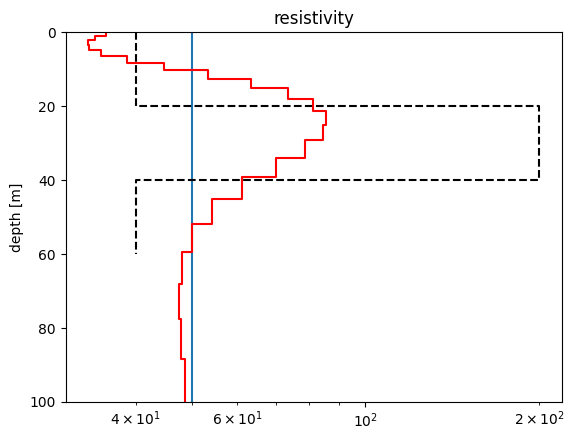

In [26]:
ax = cmd_smooth.plot()
ax = m_true.plot(axs=ax, color='k', linestyle='--')
ax = rmod.plot(axs=ax, color='r')[0]
ax.set_ylim(100, 0)
ax.set_xscale('log')